# 5주차 수정본 — 두 모델에 동일한 5-fold 적용

YOLOv8 단독과 **같은 YOLO 후보를 CNN으로 재평가하는 모델**을 비교합니다. fold별로 YOLO를 새로 학습하고 동일 가중치를 단독 모델과 hybrid에 공유하며 CNN도 새로 학습합니다. 전체 데이터로 학습된 기존 best.pt를 5-fold에 재사용하지 않습니다.

기본 CV 풀은 `train + valid`입니다. 기존 `test`는 별도 최종 평가용으로 보존합니다. 5개의 outer fold 중 1개는 성능 평가 전용이고, 남은 4개 안에서 train/inner val을 나눕니다. **inner val에서만** YOLO/CNN checkpoint 및 alpha·운영 threshold를 선택합니다. outer 평가 데이터를 모델 선택에 쓰지 않습니다.

이미지가 독립적이면 KFold(shuffle=True, seed=42), 같은 원본/동일 pixel/영상 group이 있으면 GroupKFold(5)를 자동 사용합니다. inner val도 group이 겹치지 않는 holdout입니다. 내부까지 5-fold 전체 탐색을 하는 완전 nested 5×5 CV는 아닙니다.

실제 데이터와 .pt 가중치는 이 대화에 첨부되지 않았습니다. 이전 코드의 경로·단일 클래스·Roboflow 665장이라는 메모까지만 확인되었습니다. 아래 데이터 진단 셀이 **실제 현재 이미지 수와 라벨 값**을 확인합니다.


In [1]:
%pip install -q "ultralytics>=8.3,<9" "torchmetrics>=1.4,<2" "scikit-learn>=1.3,<2" pycocotools opencv-python-headless matplotlib pandas pyyaml
from google.colab import drive
import os
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
import torch
print('GPU:',torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU; GPU 런타임 권장')


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 6.1 MB/s eta 0:00:00
Mounted at /content/drive
GPU: Tesla T4


## 1. 경로와 조건 설정


In [2]:
CFG = {
    'data_root': '/content/drive/MyDrive/Pothole',
    # train+valid만 교차검증 풀로 사용. test는 별도 최종 평가용으로 남겨둡니다.
    'cv_image_dirs': ['train/images', 'valid/images'],
    'groups_csv': '',  # 권장 CSV: path,group; path는 data_root 기준 상대경로
    'output_root': '/content/drive/MyDrive/Pothole/week5_kfold_results',
    'local_stage_root': '/content/week5_cv_staging',
    'keep_local_staging': False,
    'coordinate_eps': 1e-6,  # 최대 허용치; 큰 오류나 0-width bbox는 자동 수정하지 않음
    'inner_val_fraction': .2,
    'yolo_weights': '',  # 필수: 기존 전체 데이터의 best.pt 재사용 금지
    'yolo_init': 'yolov8s.pt', # 일반 COCO 사전학습 가중치로 fold마다 초기화
    'yolo_epochs':100, 'yolo_batch':16, 'seed':42, 'imgsz':800,
    'proposal_conf':.001, 'nms_iou':.7, 'max_det':300,
    'crop_size':96, 'cnn_epochs':30, 'cnn_patience':7, 'cnn_batch':64, 'cnn_lr':.001,
    'backgrounds_per_image':12, 'alpha_grid':[0.,.25,.5,1.],
    'shared_threshold':.25, 'bootstrap_n':2000,
    'benchmark_images':30, 'benchmark_repeats':3,
}
# GPU OOM일 때 전체 실험을 시작하기 전에 yolo_batch=8로 변경하세요.


## 2. 공통 비교 모듈 생성


In [3]:
%%writefile /content/week5_compare.py
"""Week 5: shared YOLOv8 detector + binary CNN proposal rescoring.
Run from the accompanying Colab notebook. No test labels are used for training/tuning.
"""
from pathlib import Path
import copy, csv, hashlib, json, random, time, platform, subprocess, sys
import cv2
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from ultralytics import YOLO
from torchmetrics.detection.mean_ap import MeanAveragePrecision


def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def dump(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding='utf-8')


def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''): h.update(chunk)
    return h.hexdigest()


def ious(a, b):
    a=np.asarray(a, dtype=np.float32).reshape(-1,4)
    b=np.asarray(b, dtype=np.float32).reshape(-1,4)
    lo=np.maximum(a[:,None,:2], b[None,:,:2]); hi=np.minimum(a[:,None,2:], b[None,:,2:])
    inter=np.maximum(hi-lo,0).prod(2)
    aa=np.maximum(a[:,2:]-a[:,:2],0).prod(1)
    bb=np.maximum(b[:,2:]-b[:,:2],0).prod(1)
    return inter / np.maximum(aa[:,None]+bb[None,:]-inter, 1e-9)


def audit_dataset(cfg, out):
    """Explicit YOLO directory layout; missing annotation != negative image."""
    root=Path(cfg['data_root']); records={}; fingerprints={}; manifest=[]
    for split, rel in cfg['splits'].items():
        images=root/rel
        labels=images.parent/'labels' if images.name=='images' else Path(str(images).replace('images_aug','labels_aug'))
        if labels == images: raise ValueError('Use split/images or split/images_aug directory layout')
        files=sorted(p for p in images.iterdir() if p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.webp'})
        if not files: raise ValueError(f'{split}: 이미지가 없습니다: {images}')
        rows=[]
        for p in files:
            im=cv2.imread(str(p))
            if im is None: raise ValueError(f'손상된 이미지: {p}')
            h,w=im.shape[:2]; label=labels/(p.stem+'.txt')
            if not label.exists(): raise FileNotFoundError(f'라벨 누락: {label}; 배경 이미지는 빈 txt 파일 필요')
            raw=[]
            for line in label.read_text().splitlines():
                if not line.strip(): continue
                v=list(map(float,line.split()))
                if len(v)!=5 or v[0]!=0 or not np.isfinite(v).all(): raise ValueError(f'단일 클래스 YOLO 라벨 오류: {label}')
                _,x,y,bw,bh=v
                if not (0<=x<=1 and 0<=y<=1 and 0<bw<=1 and 0<bh<=1): raise ValueError(f'좌표 오류: {label}')
                box=[(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h]
                box=np.clip(box,[0,0,0,0],[w,h,w,h]).tolist()
                if box[2]<=box[0] or box[3]<=box[1]: raise ValueError(f'빈 bbox: {label}')
                raw.append(box)
            pixel_hash=hashlib.sha256(np.asarray(im.shape,dtype=np.int64).tobytes()+im.tobytes()).hexdigest()
            if pixel_hash in fingerprints and fingerprints[pixel_hash][0]!=split:
                raise ValueError(f'split 간 동일 이미지 누수: {p}, {fingerprints[pixel_hash]}')
            fingerprints[pixel_hash]=(split,str(p))
            rows.append({'path':str(p),'gt':np.asarray(raw,dtype=np.float32).reshape(-1,4)})
            manifest.append({'split':split,'path':str(p),'label_sha256':sha(label),'pixel_sha256':pixel_hash,'objects':len(raw)})
        if sum(len(r['gt']) for r in rows)==0: raise ValueError(f'{split}: 포트홀 GT가 전혀 없습니다')
        records[split]=rows
    # Common augmented variants must stay in their original split.
    import re
    families={}
    for split,rows in records.items():
        for r in rows:
            family=re.sub(r'_envaug_\d+$','',Path(r['path']).stem)
            family=re.sub(r'\.rf\.[^.]+$','',family)
            if family in families and families[family]!=split:
                raise ValueError(f'원본/증강 family가 다른 split에 존재: {family}')
            families[family]=split
    # Optional CSV: path,group (relative to data_root). Group = source video/road/session.
    if cfg.get('groups_csv'):
        with open(cfg['groups_csv'],newline='',encoding='utf-8') as f: groups={r['path']:r['group'] for r in csv.DictReader(f)}
        used={}
        for split,rows in records.items():
            for r in rows:
                key=Path(r['path']).relative_to(root).as_posix()
                if key not in groups: raise ValueError(f'group 정보 누락: {key}')
                g=groups[key]
                if not g: raise ValueError(f'빈 group: {key}')
                if g in used and used[g]!=split: raise ValueError(f'영상/도로 group 누수: {g}')
                used[g]=split
    else:
        print('주의: 동일 영상의 인접 프레임/유사 이미지 누수는 자동 검출되지 않습니다. groups_csv로 확인하세요.')
    dump(out/'dataset_manifest.json',manifest)
    return records


class CropCNN(nn.Module):
    def __init__(self):
        super().__init__()
        blocks=[]; c=3
        for width in [32,64,128]:
            blocks += [nn.Conv2d(c,width,3,padding=1),nn.BatchNorm2d(width),nn.ReLU(),nn.MaxPool2d(2)]
            c=width
        self.net=nn.Sequential(*blocks,nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Dropout(.2),nn.Linear(128,1))
    def forward(self,x): return self.net(x).flatten()


def crop_tensor(im,box,size):
    h,w=im.shape[:2]
    x1,y1=np.floor(box[:2]).astype(int); x2,y2=np.ceil(box[2:]).astype(int)
    x1,y1=max(0,min(x1,w-1)),max(0,min(y1,h-1))
    x2,y2=max(x1+1,min(x2,w)),max(y1+1,min(y2,h))
    crop=cv2.cvtColor(cv2.resize(im[y1:y2,x1:x2],(size,size)),cv2.COLOR_BGR2RGB)
    return torch.from_numpy(crop.transpose(2,0,1).copy()).float()/255.


class Crops(Dataset):
    def __init__(self,items,size,augment=False): self.items=items; self.size=size; self.augment=augment
    def __len__(self): return len(self.items)
    def __getitem__(self,i):
        p,box,label=self.items[i]; im=cv2.imread(p)
        if im is None: raise ValueError(p)
        x=crop_tensor(im,box,self.size)
        if self.augment:
            if random.random()<.5: x=torch.flip(x,[2])
            x=(x*random.uniform(.8,1.2)).clamp(0,1)
        return x,torch.tensor(float(label))


def predict_yolo(model,im,cfg):
    r=model.predict(im,imgsz=cfg['imgsz'],conf=cfg['proposal_conf'],iou=cfg['nms_iou'],
                    max_det=cfg['max_det'],device=cfg['device'],half=False,verbose=False)[0]
    return {'boxes':r.boxes.xyxy.cpu().numpy(),'scores':r.boxes.conf.cpu().numpy()}


def make_crops(rows,det,cfg,train):
    items=[]; rng=np.random.default_rng(cfg['seed'])
    for row in rows:
        im=cv2.imread(row['path']); h,w=im.shape[:2]; gt=row['gt']
        proposals=predict_yolo(det,im,cfg)['boxes']
        if train:
            extra=list(gt.copy())
            for b in gt:
                for _ in range(2):
                    wh=b[2:]-b[:2]; jitter=rng.uniform(-.1,.1,4)*np.tile(wh,2)
                    j=np.clip(b+jitter,[0,0,0,0],[w,h,w,h])
                    if j[2]>j[0] and j[3]>j[1]: extra.append(j)
            # Training-only backgrounds; ambiguous overlap is discarded below.
            for _ in range(cfg['backgrounds_per_image']):
                bw=rng.uniform(.05,.45)*w; bh=rng.uniform(.05,.45)*h
                x=rng.uniform(0,w-bw); y=rng.uniform(0,h-bh)
                extra.append([x,y,x+bw,y+bh])
            proposals=np.concatenate([proposals,np.asarray(extra).reshape(-1,4)])
        overlap=ious(proposals,gt).max(1) if len(gt) else np.zeros(len(proposals))
        for b,v in zip(proposals,overlap):
            if v>=.5: items.append((row['path'],b.tolist(),1))
            elif v<=.1: items.append((row['path'],b.tolist(),0))
    return items


def train_cnn(det,records,cfg,out):
    train=make_crops(records['train'],det,cfg,True)
    val=make_crops(records['val'],det,cfg,False)
    counts=[sum(x[2]==k for x in train) for k in [0,1]]
    val_counts=[sum(x[2]==k for x in val) for k in [0,1]]
    if min(counts)==0 or min(val_counts)==0:
        raise ValueError(f'CNN train/val 후보에 양성·음성이 모두 필요합니다: train={counts}, val={val_counts}. split/가중치/라벨을 확인하세요.')
    dump(out/'cnn_crop_counts.json',{'train_negative_positive':counts,'val_negative_positive':[sum(x[2]==k for x in val) for k in [0,1]],'label_rule':'positive IoU>=.5; negative IoU<=.1; otherwise ignore'})
    # Save exact training crop metadata for audit; no test crops involved.
    dump(out/'cnn_train_crops.json',[{'path':p,'box':b,'label':y} for p,b,y in train])
    generator=torch.Generator().manual_seed(cfg['seed'])
    tl=DataLoader(Crops(train,cfg['crop_size'],True),batch_size=cfg['cnn_batch'],shuffle=True,num_workers=0,generator=generator)
    vl=DataLoader(Crops(val,cfg['crop_size']),batch_size=cfg['cnn_batch'],num_workers=0)
    net=CropCNN().to(cfg['torch_device']); opt=torch.optim.AdamW(net.parameters(),lr=cfg['cnn_lr'],weight_decay=1e-4)
    loss_fn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(counts[0]/counts[1],device=cfg['torch_device']))
    best=float('inf'); stale=0; history=[]
    for epoch in range(cfg['cnn_epochs']):
        net.train(); tr=0.
        for x,y in tl:
            x,y=x.to(cfg['torch_device']),y.to(cfg['torch_device']); opt.zero_grad()
            loss=loss_fn(net(x),y); loss.backward(); opt.step(); tr+=float(loss.detach())*len(y)
        net.eval(); va=0.
        with torch.inference_mode():
            for x,y in vl:
                x,y=x.to(cfg['torch_device']),y.to(cfg['torch_device']); va+=float(loss_fn(net(x),y))*len(y)
        va/=len(val); history.append({'epoch':epoch+1,'train_loss':tr/len(train),'val_loss':va})
        print(f'CNN {epoch+1}: train={tr/len(train):.4f}, val={va:.4f}')
        if va<best:
            best=va; stale=0
            torch.save({'state_dict':net.state_dict(),'crop_size':cfg['crop_size'],'normalization':'RGB float32 /255'},out/'cnn_best.pt')
        else: stale+=1
        if stale>=cfg['cnn_patience']: break
    dump(out/'cnn_history.json',history)
    net.load_state_dict(torch.load(out/'cnn_best.pt',map_location=cfg['torch_device'],weights_only=True)['state_dict'])
    return net.eval()


@torch.inference_mode()
def cnn_scores(net,im,boxes,cfg):
    if len(boxes)==0: return np.empty(0,dtype=np.float32)
    result=[]
    for start in range(0,len(boxes),cfg['cnn_batch']):
        x=torch.stack([crop_tensor(im,b,cfg['crop_size']) for b in boxes[start:start+cfg['cnn_batch']]])
        result.append(net(x.to(cfg['torch_device'])).sigmoid().cpu().numpy())
    return np.concatenate(result)


def collect(det,net,rows,cfg):
    base=[]; probs=[]
    for row in rows:
        im=cv2.imread(row['path']); p=predict_yolo(det,im,cfg)
        base.append(p); probs.append(cnn_scores(net,im,p['boxes'],cfg))
    return base,probs


def rescore(base,probs,alpha):
    return [{'boxes':p['boxes'],'scores':p['scores']*np.maximum(q,1e-8)**alpha} for p,q in zip(base,probs)]


def map_metrics(pred,rows,cfg):
    metric=MeanAveragePrecision(box_format='xyxy',iou_type='bbox',max_detection_thresholds=[1,10,cfg['max_det']])
    pp=[{'boxes':torch.tensor(p['boxes'],dtype=torch.float32),'scores':torch.tensor(p['scores'],dtype=torch.float32),'labels':torch.zeros(len(p['scores']),dtype=torch.int64)} for p in pred]
    tt=[{'boxes':torch.tensor(r['gt'],dtype=torch.float32),'labels':torch.zeros(len(r['gt']),dtype=torch.int64)} for r in rows]
    metric.update(pp,tt); m=metric.compute()
    return {k:float(m[k]) for k in ['map','map_50','map_75','map_small','map_medium','map_large']}


def counts_at(pred,rows,threshold,iou=.5):
    result=[]
    for p,r in zip(pred,rows):
        idx=np.flatnonzero(p['scores']>=threshold)
        idx=idx[np.argsort(-p['scores'][idx],kind='stable')]
        overlap=ious(p['boxes'][idx],r['gt']); used=set(); tp=0
        for ov in overlap:
            eligible=[j for j in range(len(ov)) if j not in used and ov[j]>=iou]
            if eligible:
                j=max(eligible,key=lambda j:ov[j]); used.add(j); tp+=1
        result.append([tp,len(idx)-tp,len(r['gt'])-tp])
    return np.asarray(result,dtype=np.int64)


def operating_metrics(counts):
    tp,fp,fn=np.asarray(counts).sum(0)
    p=tp/max(tp+fp,1); r=tp/max(tp+fn,1)
    return {'precision':float(p),'recall':float(r),'f1':float(2*tp/max(2*tp+fp+fn,1)),
            'tp':int(tp),'fp':int(fp),'fn':int(fn),'fp_per_image':float(fp/len(counts))}


def tune_threshold(pred,rows,cfg):
    grid=np.unique(np.r_[cfg['proposal_conf'],np.linspace(.01,.99,99)])
    values=[operating_metrics(counts_at(pred,rows,float(t)))['f1'] for t in grid]
    # deterministic tie-breaking: smallest threshold, favor recall.
    i=int(np.argmax(values)); return float(grid[i]),float(values[i])


def paired_bootstrap(base,hybrid,seed,n):
    rng=np.random.default_rng(seed); deltas=[]
    for _ in range(n):
        ix=rng.integers(0,len(base),len(base))
        deltas.append(operating_metrics(hybrid[ix])['f1']-operating_metrics(base[ix])['f1'])
    return {'delta_f1':operating_metrics(hybrid)['f1']-operating_metrics(base)['f1'],
            'ci95':np.quantile(deltas,[.025,.975]).tolist(),'resamples':n,'unit':'image; assumes independent images',
            'scope':'test sampling uncertainty only; not training-seed uncertainty'}


def sync(cfg):
    if cfg['torch_device'].startswith('cuda'): torch.cuda.synchronize()


def benchmark(det,net,rows,alpha,cfg):
    # Decode before timer; include preprocessing, YOLO, NMS, crop, CNN, score transfer.
    ims=[cv2.imread(r['path']) for r in rows[:cfg['benchmark_images']]]
    times={'YOLOv8':[],'YOLOv8+CNN':[]}
    def run(im,hybrid):
        p=predict_yolo(det,im,cfg)
        if hybrid:
            q=cnn_scores(net,im,p['boxes'],cfg); p['scores']=p['scores']*np.maximum(q,1e-8)**alpha
        return p
    for _ in range(3):
        for hybrid in [False,True]: run(ims[0],hybrid)
    for rep in range(cfg['benchmark_repeats']):
        order=[False,True] if rep%2==0 else [True,False]
        for im in ims:
            for hybrid in order:
                sync(cfg); start=time.perf_counter(); run(im,hybrid); sync(cfg)
                times['YOLOv8+CNN' if hybrid else 'YOLOv8'].append((time.perf_counter()-start)*1000)
    return {k:{'mean_ms':float(np.mean(v)),'median_ms':float(np.median(v)),'p95_ms':float(np.percentile(v,95)),
               'fps':float(1000/np.mean(v)),'samples':len(v),'scope':'in-memory single image; disk decoding excluded; FP32'} for k,v in times.items()}


def write_csv(path,rows):
    with open(path,'w',newline='',encoding='utf-8-sig') as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)


def run(cfg):
    cfg=copy.deepcopy(cfg)
    cfg['device']=0 if torch.cuda.is_available() else 'cpu'
    cfg['torch_device']='cuda:0' if torch.cuda.is_available() else 'cpu'
    if not 0<cfg['proposal_conf']<.01: raise ValueError('mAP용 proposal_conf는 0.001 권장')
    if cfg['max_det']<=10: raise ValueError('max_det > 10 필요')
    out=Path(cfg['output_root'])/f"week5_{time.strftime('%Y%m%d_%H%M%S')}_{time.time_ns()%1000000}"
    out.mkdir(parents=True,exist_ok=False); seed_all(cfg['seed']); dump(out/'config.json',cfg)
    (out/'pip_freeze.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
    dump(out/'environment.json',{'python':platform.python_version(),'torch':torch.__version__,
                                'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None})
    records=audit_dataset(cfg,out)
    if cfg['yolo_weights']:
        path=Path(cfg['yolo_weights'])
        if not path.exists(): raise FileNotFoundError(path)
        if not cfg['weights_provenance_confirmed']:
            raise ValueError('기존 YOLO 가중치가 test를 학습/모델 선택에 사용하지 않았는지 확인하고 weights_provenance_confirmed=True로 설정하세요')
        det=YOLO(str(path))
        if det.task!='detect' or len(det.names)!=1: raise ValueError('포트홀 단일 클래스 detect 가중치 필요')
    else:
        if any(Path(rel).name!='images' for rel in cfg['splits'].values()):
            raise ValueError('YOLO 신규 학습은 표준 split/images 및 split/labels 구조가 필요합니다. 증강 데이터를 별도 루트의 표준 폴더로 정리하세요.')
        data={'path':str(Path(cfg['data_root']).resolve()),'train':cfg['splits']['train'],'val':cfg['splits']['val'],'test':cfg['splits']['test'],'names':{0:'pothole'}}
        import yaml
        yaml_path=out/'data.yaml'; yaml_path.write_text(yaml.safe_dump(data,allow_unicode=True))
        det=YOLO(cfg['yolo_init'])
        det.train(data=str(yaml_path),epochs=cfg['yolo_epochs'],patience=20,imgsz=cfg['imgsz'],batch=cfg['yolo_batch'],
                  optimizer='AdamW',lr0=.001,lrf=.01,cos_lr=True,hsv_h=.015,hsv_s=.5,hsv_v=.4,scale=.5,
                  flipud=0.,fliplr=.5,close_mosaic=15,seed=cfg['seed'],deterministic=True,
                  device=cfg['device'],project=str(out),name='detector',exist_ok=False)
        path=Path(det.trainer.best); det=YOLO(str(path))
    dump(out/'detector_provenance.json',{'weights_path':str(path),'sha256':sha(path),
                                        'reuse':bool(cfg['yolo_weights']),'user_confirmed_no_test_training':cfg['weights_provenance_confirmed']})
    # Exact same detector instance/weights serves both methods.
    net=train_cnn(det,records,cfg,out)
    vb,vq=collect(det,net,records['val'],cfg)
    trials=[]
    for alpha in cfg['alpha_grid']:
        p=rescore(vb,vq,alpha); m=map_metrics(p,records['val'],cfg)
        trials.append({'alpha':alpha,**m})
    # alpha=0 is an explicit no-CNN-effect control. Equal mAP selects it.
    best=max(trials,key=lambda x:(x['map'],-x['alpha'])); alpha=best['alpha']
    vh=rescore(vb,vq,alpha)
    t0,f0=tune_threshold(vb,records['val'],cfg); t1,f1=tune_threshold(vh,records['val'],cfg)
    locked={'alpha':alpha,'yolo_threshold':t0,'hybrid_threshold':t1,'validation_f1':[f0,f1],
            'selection':'alpha: val COCO mAP50-95; thresholds: val F1 at IoU .5',
            'alpha_zero_means':'CNN did not improve validation mAP; no accuracy gain should be claimed'}
    dump(out/'locked_validation_settings.json',locked); write_csv(out/'validation_alpha_trials.csv',trials)
    # Test is first inferred here, after all model/threshold choices have been frozen.
    tb,tq=collect(det,net,records['test'],cfg); th=rescore(tb,tq,alpha)
    speed=benchmark(det,net,records['test'],alpha,cfg); summaries=[]; counts=[]
    for name,p,t in [('YOLOv8',tb,t0),('YOLOv8+CNN',th,t1)]:
        c=counts_at(p,records['test'],t); counts.append(c)
        summaries.append({'model':name,'threshold':t,'alpha':0 if name=='YOLOv8' else alpha,
                          **map_metrics(p,records['test'],cfg),**operating_metrics(c),**{k:v for k,v in speed[name].items() if k not in ['scope']}})
    write_csv(out/'test_comparison.csv',summaries)
    shared=[{'model':n,'threshold':cfg['shared_threshold'],**operating_metrics(counts_at(p,records['test'],cfg['shared_threshold']))}
            for n,p in [('YOLOv8',tb),('YOLOv8+CNN',th)]]
    write_csv(out/'test_shared_threshold.csv',shared)
    dump(out/'paired_bootstrap_f1.json',paired_bootstrap(*counts,cfg['seed'],cfg['bootstrap_n']))
    dump(out/'latency.json',speed)
    per_image=[]; predictions=[]
    for i,r in enumerate(records['test']):
        per_image.append({'image':r['path'],'gt':len(r['gt']),**{f'{name}_{field}':int(counts[j][i,k]) for j,name in enumerate(['yolo','hybrid']) for k,field in enumerate(['tp','fp','fn'])}})
        predictions.append({'image':r['path'],'gt':r['gt'].tolist(),'boxes':tb[i]['boxes'].tolist(),
                            'yolo_scores':tb[i]['scores'].tolist(),'cnn_probs':tq[i].tolist(),'hybrid_scores':th[i]['scores'].tolist()})
    write_csv(out/'test_per_image.csv',per_image); dump(out/'test_predictions.json',predictions)
    # Error cases selected only for reporting, after settings have been locked.
    case_dir=out/'error_cases'; case_dir.mkdir()
    worst=sorted(range(len(per_image)),key=lambda i:per_image[i]['yolo_fp']+per_image[i]['hybrid_fp']+per_image[i]['hybrid_fn'],reverse=True)[:8]
    for rank,i in enumerate(worst):
        panels=[]
        for name,p,t in [('YOLOv8',tb[i],t0),('YOLOv8+CNN',th[i],t1)]:
            im=cv2.imread(records['test'][i]['path'])
            for box in records['test'][i]['gt']:
                x1,y1,x2,y2=box.astype(int); cv2.rectangle(im,(x1,y1),(x2,y2),(0,255,0),2)
            for box,score in zip(p['boxes'],p['scores']):
                if score<t: continue
                x1,y1,x2,y2=box.astype(int); cv2.rectangle(im,(x1,y1),(x2,y2),(0,0,255),2)
                cv2.putText(im,f'{score:.2f}',(x1,max(16,y1)),cv2.FONT_HERSHEY_SIMPLEX,.5,(0,0,255),1)
            cv2.putText(im,name,(8,24),cv2.FONT_HERSHEY_SIMPLEX,.7,(255,255,255),2)
            panels.append(im)
        cv2.imwrite(str(case_dir/f'{rank:02d}.jpg'),np.concatenate(panels,axis=1))
    import matplotlib.pyplot as plt
    fig,axs=plt.subplots(1,2,figsize=(11,4))
    metrics=['map_50','map','precision','recall','f1']; x=np.arange(len(metrics))
    for j,r in enumerate(summaries): axs[0].bar(x+(j-.5)*.35,[r[k] for k in metrics],width=.35,label=r['model'])
    axs[0].set_xticks(x,metrics); axs[0].set_ylim(0,1); axs[0].legend(); axs[0].set_title('Held-out test: detection metrics')
    axs[1].bar([r['model'] for r in summaries],[r['mean_ms'] for r in summaries]); axs[1].set_ylabel('ms / image'); axs[1].set_title('YOLO + crop + CNN; disk decode excluded')
    fig.tight_layout(); fig.savefig(out/'comparison.png',dpi=180); plt.close(fig)
    for r in summaries: print(r)
    print('선택된 alpha:',alpha,'| 결과 폴더:',out)
    return out,summaries


Writing /content/week5_compare.py


## 3. 라벨 진단 및 5-fold 모듈 생성


In [4]:
%%writefile /content/week5_kfold.py
"""Paired outer 5-fold CV with an inner holdout for checkpoint/score selection.
Train+valid are the default CV pool. Existing test is untouched by CV training.
"""
from pathlib import Path
import csv, hashlib, json, re, shutil, time
import numpy as np
import cv2
from sklearn.model_selection import KFold, GroupKFold, GroupShuffleSplit
import week5_compare as common

SUFFIXES={'.jpg','.jpeg','.png','.bmp','.webp'}


def validate_label_line(line, label, line_no, eps=1e-6):
    try: v=np.asarray([float(x) for x in line.split()],dtype=np.float64)
    except ValueError as e: raise ValueError(f'{label}:{line_no}: 숫자가 아닌 라벨: {line!r}') from e
    if len(v)!=5 or not np.isfinite(v).all() or v[0]!=0:
        raise ValueError(f'{label}:{line_no}: [class=0,x,y,w,h] 형식 필요; 실제 값={v.tolist()}')
    _,x,y,w,h=v
    if not (-eps<=x<=1+eps and -eps<=y<=1+eps and 0<w<=1+eps and 0<h<=1+eps):
        raise ValueError(f'{label}:{line_no}: 좌표 범위 오류; x={x}, y={y}, w={w}, h={h}; '
                         'x/y는 [0,1], w/h는 (0,1]. 큰 오류는 원본 annotation에서 수정해야 합니다.')
    fixed=v.copy(); fixed[1:]=np.clip(fixed[1:],0,1)
    return fixed, not np.array_equal(v,fixed)


def diagnose_labels(root, image_dirs, report_path=None):
    """Scan all invalid rows without modifying or skipping source labels."""
    root=Path(root); errors=[]; tiny=[]; stats={}
    for rel in image_dirs:
        images=root/rel; labels=images.parent/'labels'
        if images.name=='images_aug': labels=images.parent/'labels_aug'
        if not images.is_dir():
            errors.append({'file':str(images),'line':0,'raw':'','reason':'image directory missing'}); continue
        paths=sorted(p for p in images.iterdir() if p.suffix.lower() in SUFFIXES)
        stats[rel]={'images':len(paths),'empty_labels':0,'objects':0}
        for p in paths:
            label=labels/(p.stem+'.txt')
            if not label.exists():
                errors.append({'file':str(label),'line':0,'raw':'','reason':'label missing'}); continue
            lines=[(i,l) for i,l in enumerate(label.read_text().splitlines(),1) if l.strip()]
            if not lines: stats[rel]['empty_labels']+=1
            for i,line in lines:
                try:
                    _,corrected=validate_label_line(line,label,i)
                    stats[rel]['objects']+=1
                    if corrected: tiny.append({'file':str(label),'line':i,'raw':line,'reason':'<=1e-6 boundary overflow'})
                except ValueError as e:
                    errors.append({'file':str(label),'line':i,'raw':line,'reason':str(e)})
    result={'stats':stats,'errors':errors,'tiny_boundary_overflows':tiny}
    if report_path: common.dump(report_path,result)
    print('Dataset:',stats); print('Invalid rows:',len(errors),'| tiny boundary overflows:',len(tiny))
    for e in errors[:20]: print(e)
    return result


def family_name(path):
    stem=Path(path).stem
    stem=re.sub(r'_envaug_\d+$','',stem)
    return re.sub(r'\.rf\.[^.]+$','',stem)


def read_pool(cfg,out):
    root=Path(cfg['data_root']); rows=[]; corrections=[]; mapping={}
    if cfg.get('groups_csv'):
        with open(cfg['groups_csv'],newline='',encoding='utf-8') as f:
            for r in csv.DictReader(f):
                if 'path' not in r or 'group' not in r or not r['group']:
                    raise ValueError('groups_csv에 path,group 열과 비어 있지 않은 group 필요')
                mapping[r['path']]=r['group']
    for rel in cfg['cv_image_dirs']:
        images=root/rel
        if images.name!='images': raise ValueError('CV는 원본 split/images를 사용합니다. 증강은 분할 후 train에만 적용하세요.')
        paths=sorted(p for p in images.iterdir() if p.suffix.lower() in SUFFIXES)
        if not paths: raise ValueError(f'빈 이미지 폴더: {images}')
        for p in paths:
            if re.search(r'_envaug_\d+$',p.stem): raise ValueError(f'사전 증강 이미지가 CV pool에 포함됨: {p}; 원본만 사용하세요.')
            label=images.parent/'labels'/(p.stem+'.txt')
            if not label.exists(): raise FileNotFoundError(f'라벨 누락: {label}; 배경은 빈 txt 필요')
            im=cv2.imread(str(p))
            if im is None: raise ValueError(f'이미지 디코딩 실패: {p}')
            h,w=im.shape[:2]; gt=[]; canonical=[]
            for i,line in enumerate(label.read_text().splitlines(),1):
                if not line.strip(): continue
                v,tiny=validate_label_line(line,label,i,cfg['coordinate_eps'])
                _,x,y,bw,bh=v
                box=np.array([(x-bw/2)*w,(y-bh/2)*h,(x+bw/2)*w,(y+bh/2)*h])
                box=np.clip(box,[0,0,0,0],[w,h,w,h])
                if box[2]<=box[0] or box[3]<=box[1]: raise ValueError(f'{label}:{i}: 이미지 경계에 클립한 박스의 면적이 0')
                x1,y1,x2,y2=box
                cv=[0,(x1+x2)/(2*w),(y1+y2)/(2*h),(x2-x1)/w,(y2-y1)/h]
                if tiny or not np.allclose(v,cv,rtol=0,atol=1e-12):
                    corrections.append({'label':str(label),'line':i,'original':line,'staged_values':cv,
                                        'reason':'tiny overflow or bbox crosses image boundary'})
                canonical.append(' '.join(f'{a:.12g}' for a in cv)); gt.append(box.tolist())
            rel_path=p.relative_to(root).as_posix()
            if mapping and rel_path not in mapping: raise ValueError(f'groups_csv 경로 누락: {rel_path}')
            pixel=hashlib.sha256(np.asarray(im.shape,dtype=np.int64).tobytes()+im.tobytes()).hexdigest()
            rows.append({'path':str(p),'relative_path':rel_path,'gt':np.asarray(gt,dtype=np.float32).reshape(-1,4),
                         'canonical_label':'\n'.join(canonical)+'\n' if canonical else '',
                         'label_sha256':common.sha(label),'pixel_sha256':pixel,'family':family_name(p),
                         'provided_group':mapping.get(rel_path),'width':w,'height':h})
    if len({r['path'] for r in rows})!=len(rows): raise ValueError('cv_image_dirs에 중복 경로가 있습니다')
    # Merge exact pixel duplicates, known augmentation families, and user groups.
    parent=list(range(len(rows)))
    def find(i):
        while parent[i]!=i: parent[i]=parent[parent[i]]; i=parent[i]
        return i
    def union(a,b): parent[find(a)]=find(b)
    seen={}; pix_gt={}
    for i,r in enumerate(rows):
        if r['pixel_sha256'] in pix_gt:
            old=rows[pix_gt[r['pixel_sha256']]]['gt']
            if old.shape!=r['gt'].shape or not np.allclose(old,r['gt'],atol=.01):
                raise ValueError(f'동일 이미지에 서로 다른 GT: {r["path"]}; 중복 annotation 정리 필요')
        pix_gt[r['pixel_sha256']]=i
        keys=[('pixel',r['pixel_sha256']),('family',r['family'])]
        if r['provided_group'] is not None: keys.append(('user',r['provided_group']))
        for key in keys:
            if key in seen: union(i,seen[key])
            else: seen[key]=i
    for i,r in enumerate(rows): r['group']=f'g{find(i):06d}'
    common.dump(out/'coordinate_corrections.json',corrections)
    common.dump(out/'source_manifest.json',[{k:v for k,v in r.items() if k not in ['gt','canonical_label']} for r in rows])
    print(f'CV pool: {len(rows)} images, {sum(len(r["gt"]) for r in rows)} objects, {len(set(r["group"] for r in rows))} groups')
    print('원본 파일 수정 없음; 허용 가능한 경계 보정:',len(corrections))
    if not mapping: print('주의: 파일명/동일 pixel 그룹만 확인했습니다. 영상 인접 프레임은 groups_csv로 묶으세요.')
    return rows


def split_indices(rows,cfg):
    n=len(rows); groups=np.array([r['group'] for r in rows]); ix=np.arange(n)
    grouped=len(set(groups))<n or bool(cfg.get('groups_csv'))
    if len(set(groups))<5: raise ValueError('5-fold에 서로 독립적인 group 최소 5개 필요')
    splitter=GroupKFold(n_splits=5) if grouped else KFold(n_splits=5,shuffle=True,random_state=cfg['seed'])
    outer=list(splitter.split(ix,groups=groups) if grouped else splitter.split(ix))
    folds=[]
    for fold,(dev,test) in enumerate(outer,1):
        # One inner holdout, not a second full 5-fold grid search.
        gss=GroupShuffleSplit(n_splits=1,test_size=cfg['inner_val_fraction'],random_state=cfg['seed']+fold)
        fit_local,val_local=next(gss.split(dev,groups=groups[dev]))
        fit,val=dev[fit_local],dev[val_local]
        for a,b in [(fit,val),(fit,test),(val,test)]:
            assert not set(groups[a])&set(groups[b])
        if any(sum(len(rows[i]['gt']) for i in indices)==0 for indices in [fit,val,test]):
            raise ValueError(f'fold {fold}: train/inner_val/outer_test 중 GT가 없는 split 존재. group 구성/데이터 분포 확인 필요')
        folds.append({'fold':fold,'train':fit.tolist(),'val':val.tolist(),'test':test.tolist()})
    assert sorted(i for f in folds for i in f['test'])==list(range(n))
    return folds,'GroupKFold' if grouped else 'KFold'


def stage_fold(rows,fold,dest):
    dest=Path(dest); dest.mkdir(parents=True,exist_ok=False)
    manifest=[]
    for split in ['train','val','test']:
        for sub in ['images','labels']: (dest/split/sub).mkdir(parents=True)
        for i in fold[split]:
            r=rows[i]; name=f'{i:06d}'+Path(r['path']).suffix.lower()
            # copy into ephemeral Colab workspace, never change Drive sources.
            shutil.copy2(r['path'],dest/split/'images'/name)
            (dest/split/'labels'/f'{i:06d}.txt').write_text(r['canonical_label'])
            manifest.append({'split':split,'staged_path':f'{split}/images/{name}',
                             'source_path':r['path'],'index':i,'group':r['group']})
    return manifest


def group_bootstrap_f1(counts0,counts1,groups,seed,n):
    rng=np.random.default_rng(seed); groups=np.asarray(groups); unique=sorted(set(groups))
    a=np.array([counts0[groups==g].sum(0) for g in unique]); b=np.array([counts1[groups==g].sum(0) for g in unique])
    delta=[]
    for _ in range(n):
        ix=rng.integers(0,len(unique),len(unique))
        delta.append(common.operating_metrics(b[ix])['f1']-common.operating_metrics(a[ix])['f1'])
    return {'delta_f1':common.operating_metrics(counts1)['f1']-common.operating_metrics(counts0)['f1'],
            'ci95':np.quantile(delta,[.025,.975]).tolist(),'unit':'known group','groups':len(unique),
            'resamples':n,'scope':'OOF descriptive sampling interval; CV training sets overlap; not a significance test'}


def run_kfold(cfg):
    cfg=dict(cfg)
    if cfg.get('yolo_weights'): raise ValueError('5-fold에서는 전체 데이터로 학습된 best.pt를 재사용할 수 없습니다. yolo_weights="" 필요')
    if cfg['coordinate_eps']<0 or cfg['coordinate_eps']>1e-6: raise ValueError('coordinate_eps는 0~1e-6만 허용')
    out=Path(cfg['output_root'])/f'kfold5_{time.strftime("%Y%m%d_%H%M%S")}_{time.time_ns()%1000000}'
    out.mkdir(parents=True,exist_ok=False); common.dump(out/'cv_config.json',cfg)
    rows=read_pool(cfg,out); folds,method=split_indices(rows,cfg)
    common.dump(out/'fold_indices.json',{'method':method,'folds':folds,'inner':'single group holdout',
                                        'fixed_test_policy':'not used unless explicitly in cv_image_dirs'})
    all_results=[]; oof=[None]*len(rows); oof_counts=[None]*len(rows)
    for fold in folds:
        k=fold['fold']; print(f'===== Fold {k}/5: train={len(fold["train"])}, inner_val={len(fold["val"])}, outer_test={len(fold["test"])} =====')
        stage=Path(cfg['local_stage_root'])/out.name/f'fold{k}'
        provenance=stage_fold(rows,fold,stage)
        fold_root=out/f'fold{k}'; fold_root.mkdir()
        common.dump(fold_root/'stage_manifest.json',provenance)
        fold_cfg={**cfg,'data_root':str(stage),'splits':{'train':'train/images','val':'val/images','test':'test/images'},
                  'groups_csv':'','output_root':str(fold_root),'yolo_weights':'','seed':cfg['seed']+k,
                  'weights_provenance_confirmed':False}
        run_out,results=common.run(fold_cfg)
        for r in results: all_results.append({'fold':k,**r})
        predictions=json.loads((run_out/'test_predictions.json').read_text())
        by_index={int(Path(p['image']).stem):p for p in predictions}
        with open(run_out/'test_per_image.csv',newline='',encoding='utf-8-sig') as f:
            count_rows={int(Path(r['image']).stem):r for r in csv.DictReader(f)}
        base_counts=[]; hybrid_counts=[]; test_groups=[]
        for i in fold['test']:
            p=by_index[i]; p['image']=rows[i]['path']; p['fold']=k; oof[i]=p
            r=count_rows[i]
            pair=[[int(r[f'{m}_{key}']) for key in ['tp','fp','fn']] for m in ['yolo','hybrid']]
            oof_counts[i]=pair; base_counts.append(pair[0]); hybrid_counts.append(pair[1]); test_groups.append(rows[i]['group'])
        # Replace the single-run IID image interval with the actual grouping interval.
        common.dump(run_out/'paired_bootstrap_f1.json',group_bootstrap_f1(np.array(base_counts),np.array(hybrid_counts),test_groups,cfg['seed']+k,cfg['bootstrap_n']))
        common.write_csv(out/'cv_fold_results.csv',all_results)
        common.dump(out/'completed_folds.json',{'completed':k,'total':5})
        if not cfg['keep_local_staging']:
            shutil.rmtree(stage)  # only this run's freshly created local staging folder
        if common.torch.cuda.is_available(): common.torch.cuda.empty_cache()
    # Every original image has exactly one outer-holdout prediction from an unseen detector.
    common.dump(out/'oof_predictions.json',oof)
    metric_names=['map_50','map','precision','recall','f1','fp_per_image','mean_ms','fps']
    summary=[]; differences=[]
    for model in ['YOLOv8','YOLOv8+CNN']:
        rs=[r for r in all_results if r['model']==model]
        for metric in metric_names:
            values=np.array([r[metric] for r in rs])
            summary.append({'model':model,'metric':metric,'mean':float(values.mean()),'std_ddof1':float(values.std(ddof=1)),'folds':5})
    for k in range(1,6):
        rs={r['model']:r for r in all_results if r['fold']==k}
        differences.append({'fold':k,**{f'delta_{m}':rs['YOLOv8+CNN'][m]-rs['YOLOv8'][m] for m in metric_names}})
    common.write_csv(out/'cv_summary_mean_std.csv',summary)
    common.write_csv(out/'cv_paired_fold_deltas.csv',differences)
    counts=np.array(oof_counts)
    common.dump(out/'oof_paired_group_bootstrap_f1.json',group_bootstrap_f1(counts[:,0],counts[:,1],
                                                                      [r['group'] for r in rows],cfg['seed'],cfg['bootstrap_n']))
    # Pooled OOF AP is descriptive: fold-specific score scales may differ. Fold mean/std is primary.
    target=[{'gt':np.array(p['gt'],dtype=np.float32).reshape(-1,4)} for p in oof]
    oof_result=[]
    for model,score in [('YOLOv8','yolo_scores'),('YOLOv8+CNN','hybrid_scores')]:
        pred=[{'boxes':np.array(p['boxes'],dtype=np.float32).reshape(-1,4),'scores':np.array(p[score],dtype=np.float32)} for p in oof]
        j=0 if model=='YOLOv8' else 1
        oof_result.append({'model':model,**common.map_metrics(pred,target,cfg),**common.operating_metrics(counts[:,j])})
    common.write_csv(out/'oof_descriptive_metrics.csv',oof_result)
    import matplotlib.pyplot as plt
    fig,axs=plt.subplots(1,2,figsize=(11,4))
    for model in ['YOLOv8','YOLOv8+CNN']:
        rs=[r for r in all_results if r['model']==model]
        axs[0].plot([r['fold'] for r in rs],[r['map'] for r in rs],marker='o',label=model)
        axs[1].plot([r['fold'] for r in rs],[r['f1'] for r in rs],marker='o',label=model)
    for ax,title in zip(axs,['Outer held-out mAP50-95','Outer held-out F1']):
        ax.set_xlabel('Fold'); ax.set_xticks(range(1,6)); ax.set_ylim(0,1); ax.set_title(title); ax.legend()
    fig.tight_layout(); fig.savefig(out/'cv_comparison.png',dpi=180); plt.close(fig)
    print('완료:',out); return out,all_results


Writing /content/week5_kfold.py


## 4. 실제 라벨 값·데이터 수 확인
오류의 실제 값을 확인하고 큰 annotation 오류는 원본에서 수정하세요.


In [5]:
import sys, importlib
from pathlib import Path
if '/content' not in sys.path: sys.path.insert(0,'/content')
import week5_compare, week5_kfold
importlib.reload(week5_compare)
importlib.reload(week5_kfold) # 기존 런타임에 같은 이름 모듈이 있어도 최신 코드 사용

# 질문에 나온 라벨의 실제 값을 먼저 확인합니다.
bad = Path(CFG['data_root'])/'test/labels/img-415_jpg.rf.2285ec32b9bdc584221e193dc135e3fd.txt'
if bad.exists():
    print('문제가 난 파일:',bad)
    for no,line in enumerate(bad.read_text().splitlines(),1): print(no,repr(line))
else:
    print('질문에 나온 파일이 현재 경로에 없습니다:',bad)

Path(CFG['output_root']).mkdir(parents=True,exist_ok=True)
LABEL_REPORT = week5_kfold.diagnose_labels(
    CFG['data_root'], list(dict.fromkeys(CFG['cv_image_dirs']+['test/images'])),
    Path(CFG['output_root'])/'label_diagnostics.json'
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
문제가 난 파일: /content/drive/MyDrive/Pothole/test/labels/img-415_jpg.rf.2285ec32b9bdc584221e193dc135e3fd.txt
1 '0 0.51125 0.5333333333333333 0.2775 0.15333333333333332'
2 '0 0.3 0.29 0.185 0.06'
3 '0 0.68 0.545 0 0.0033333333333333335'
Dataset: {'train/images': {'images': 465, 'empty_labels': 0, 'objects': 1256}, 'valid/images': {'images': 133, 'empty_labels': 0, 'objects': 330}, 'test/images': {'images': 67, 'empty_labels': 0, 'objects': 153}}
Invalid rows: 1 | tiny boundary overflows: 0
{'file': '/content/drive/MyDrive/Pothole/test/labels/img-415_jpg.rf.2285ec32b9bdc584221e193dc135e3fd.txt', 'line': 3, 'raw': '0 0.68 0.545 0 0.0033333333333333335', 'reason': '/content/drive/MyDrive/Pothole/test/label

## 라벨 오류를 읽는 방법

YOLO 라벨 한 줄은 `class_id x_center y_center width height`이며 좌표는 정규화 값입니다. class는 포트홀 0, 중심 x/y는 [0,1], 너비/높이는 (0,1]이어야 합니다.

- `width=1.0000001` 등 1e-6 이하 경계 초과는 작은 수치 오차로 처리할 수 있습니다.
- 너비/높이=0, 음수, `640 320 ...` 같은 픽셀 좌표, 큰 초과 값은 임의로 clamp하거나 삭제하지 않습니다. 원 annotation과 이미지 크기를 확인하고 재내보내야 합니다.
- `LABEL_REPORT['errors']`에 파일·줄·원문·이유를 저장합니다. test 오류만 있으면 train+valid CV는 진행할 수 있지만, 별도 test 평가 전에 반드시 해결해야 합니다.
- CV 소스는 수정하지 않습니다. 유효한 박스가 이미지 경계를 넘어가면 경계로 클립하고, 필요한 작은 수치 보정을 별도 staging 라벨에만 기록합니다. `coordinate_corrections.json`에서 수정 내역을 확인하세요. width/height가 0인 박스는 건너뛰지 않고 중단합니다.
- 배경 이미지에는 빈 txt 라벨이 있어야 하며, 라벨 누락은 배경으로 간주하지 않습니다.

## 데이터 분할 조건

`groups_csv` 예시:
```
path,group
train/images/frame_001.jpg,road_video_A
valid/images/frame_002.jpg,road_video_A
train/images/frame_003.jpg,road_video_B
```
동일 영상의 인접 프레임, 같은 원본의 증강본은 같은 group으로 지정하세요. 파일명이 다르고 이미지 픽셀이 달라지면 자동 family/hash 검사만으로 유사 프레임을 찾을 수 없습니다.

오프라인 `_envaug_` 데이터는 pool에서 제외하고 원본 `split/images`로 분할합니다. YOLO 학습 증강과 CNN crop 증강은 fold의 train에만 적용됩니다. Roboflow 사전 증강본이 이미 들어 있다면 원본으로 구성하거나 정확한 원본 group을 제공하고 해석에 그 사실을 밝히세요. 숫자로 재명명한 표준 `images/labels` staging 구조로 복사하므로 이전 `images_aug` 라벨 경로 문제도 피합니다.

원본 `test`까지 5-fold 풀에 넣고 싶다면 실험 전에 `cv_image_dirs`에 `test/images`를 추가할 수 있습니다. 이때 기존 test는 더 이상 독립 최종 평가셋이 아니며, 해당 오류 라벨부터 수정해야 합니다.


## 5. 동일 분할로 두 모델을 학습·평가


In [6]:
OUT_CV, FOLD_RESULTS = week5_kfold.run_kfold(CFG)


스트리밍 출력 내용이 길어서 마지막 5000줄이 삭제되었습니다.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in

## 6. fold별 결과와 평균±표준편차


,fold,model,threshold,alpha,map,map_50,map_75,map_small,map_medium,map_large,...,f1,tp,fp,fn,fp_per_image,mean_ms,median_ms,p95_ms,fps,samples
0,1,YOLOv8,0.58,0.0,-1.0,0.717064,0.504639,0.181141,0.408133,0.592451,...,0.693578,189,51,116,0.425000,28.843085,28.731019,30.261696,34.670355,90
1,1,YOLOv8+CNN,0.58,0.0,-1.0,0.717064,0.504639,0.181141,0.408133,0.592451,...,0.693578,189,51,116,0.425000,40.105098,39.432973,48.524528,24.934486,90
2,2,YOLOv8,0.35,0.0,-1.0,0.721632,0.478747,0.378343,0.343573,0.545972,...,0.683871,159,53,94,0.441667,28.508602,28.549452,29.873638,35.077132,90
3,2,YOLOv8+CNN,0.35,0.0,-1.0,0.721632,0.478747,0.378343,0.343573,0.545972,...,0.683871,159,53,94,0.441667,40.527211,39.323890,51.208309,24.674780,90
4,3,YOLOv8,0.45,0.0,-1.0,0.755665,0.536944,0.323416,0.448747,0.577435,...,0.726655,214,56,105,0.466667,28.642452,28.580082,30.108350,34.913212,90
5,3,YOLOv8+CNN,0.45,0.0,-1.0,0.755665,0.536944,0.323416,0.448747,0.577435,...,0.726655,214,56,105,0.466667,41.552818,40.950541,53.431115,24.065756,90
6,4,YOLOv8,0.61,0.0,-1.0,0.741933,0.533584,0.332796,0.451077,0.604241,...,0.733746,237,39,133,0.327731,28.244523,28.816508,30.421451,35.405094,90
7,4,YOLOv8+CNN,0.61,0.0,-1.0,0.741933,0.533584,0.332796,0.451077,0.604241,...,0.733746,237,39,133,0.327731,39.371732,39.102339,52.570258,25.398933,90
8,5,YOLOv8,0.40,0.0,-1.0,0.737364,0.498508,0.322360,0.449694,0.593180,...,0.715822,233,79,106,0.663866,28.904084,28.861030,30.164878,34.597187,90
9,5,YOLOv8+CNN,0.40,0.0,-1.0,0.737364,0.498508,0.322360,0.449694,0.593180,...,0.715822,233,79,106,0.663866,41.259295,41.289688,52.119759,24.236963,90


,model,metric,mean,std_ddof1,folds
0,YOLOv8,map_50,0.734732,0.015658,5
1,YOLOv8,map,-1.000000,0.000000,5
2,YOLOv8,precision,0.787117,0.045159,5
3,YOLOv8,recall,0.649367,0.028716,5
4,YOLOv8,f1,0.710734,0.021359,5
5,YOLOv8,fp_per_image,0.464986,0.123022,5
6,YOLOv8,mean_ms,28.628549,0.266459,5
7,YOLOv8,fps,34.932596,0.326263,5
8,YOLOv8+CNN,map_50,0.734732,0.015658,5
9,YOLOv8+CNN,map,-1.000000,0.000000,5


,fold,delta_map_50,delta_map,delta_precision,delta_recall,delta_f1,delta_fp_per_image,delta_mean_ms,delta_fps
0,1,0.0,0.0,0.0,0.0,0.0,0.0,11.262013,-9.735869
1,2,0.0,0.0,0.0,0.0,0.0,0.0,12.018609,-10.402353
2,3,0.0,0.0,0.0,0.0,0.0,0.0,12.910366,-10.847456
3,4,0.0,0.0,0.0,0.0,0.0,0.0,11.127209,-10.006161
4,5,0.0,0.0,0.0,0.0,0.0,0.0,12.355211,-10.360224


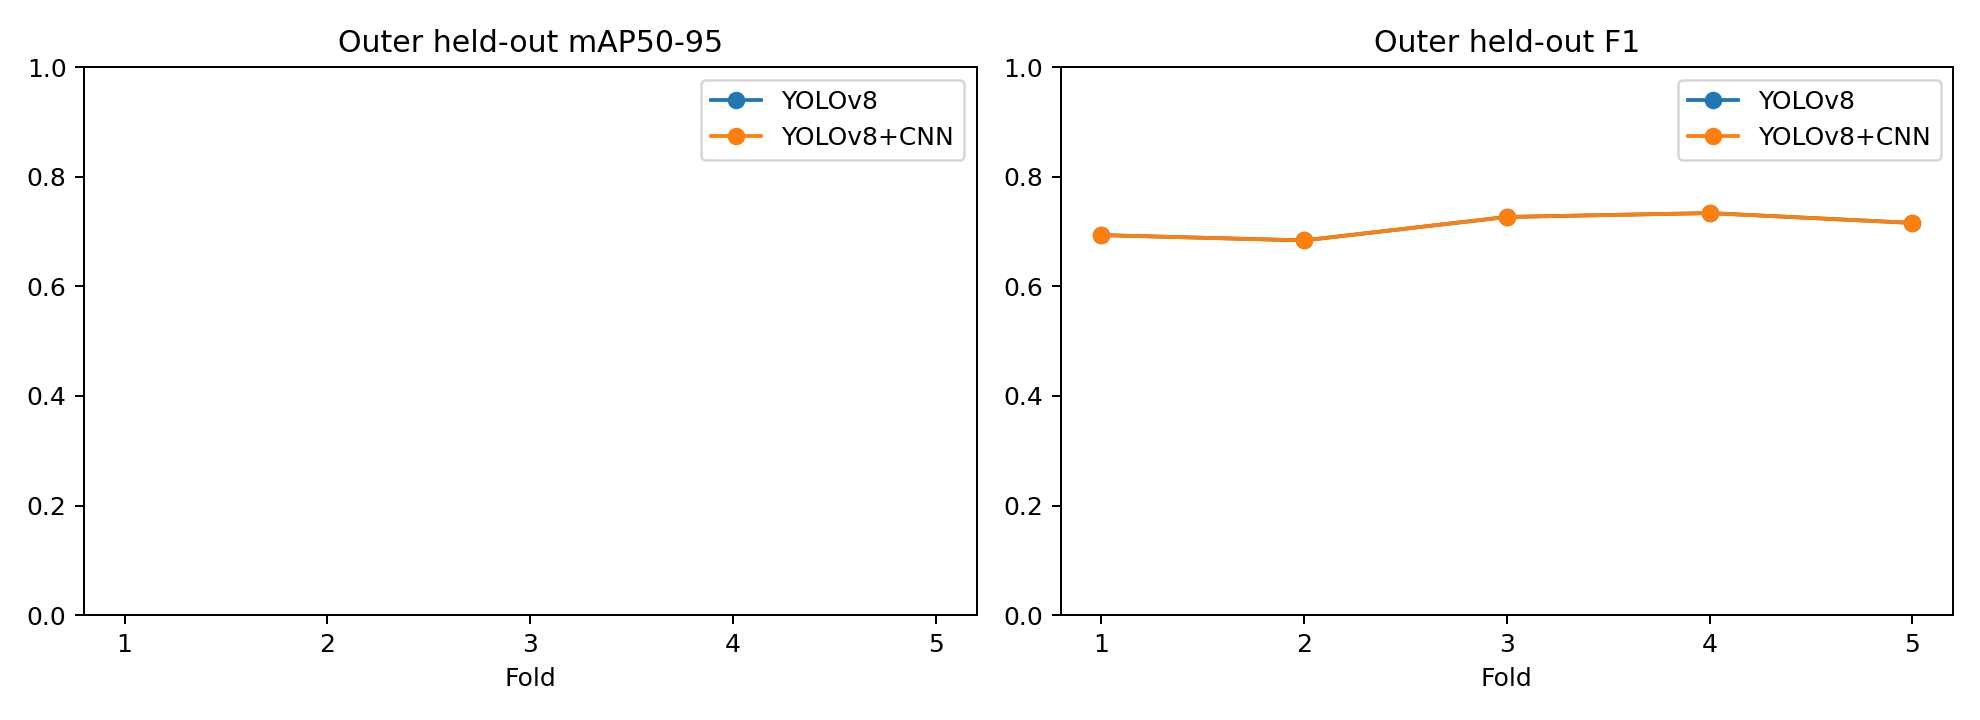

결과 폴더: /content/drive/MyDrive/Pothole/week5_kfold_results/kfold5_20261020_122553_759159


In [7]:
import pandas as pd
from IPython.display import display, Image
fold_table = pd.read_csv(OUT_CV/'cv_fold_results.csv')
summary = pd.read_csv(OUT_CV/'cv_summary_mean_std.csv')
display(fold_table)
display(summary)
display(pd.read_csv(OUT_CV/'cv_paired_fold_deltas.csv'))
display(Image(filename=str(OUT_CV/'cv_comparison.png')))
print('결과 폴더:',OUT_CV)


## 결과 해석과 실행 비용

- **주 결과**: `cv_fold_results.csv`, `cv_summary_mean_std.csv`의 fold별 값 및 5-fold 평균±표본 표준편차(ddof=1). mAP/F1은 0~1이며 %로 표기할 때 100을 곱합니다. 두 모델의 차이는 %p입니다.
- `cv_paired_fold_deltas.csv`는 같은 fold에서 hybrid−YOLO 차이를 제공합니다. AP, F1, FP/image, 지연시간을 함께 평가하세요. FP 감소와 Recall 감소를 모두 확인합니다.
- `fold_indices.json` 및 `source_manifest.json`은 실제 분할·group을 보존합니다. 모든 pool 이미지가 정확히 한 번 outer holdout에 속합니다.
- 각 fold에 YOLO/CNN 가중치, inner val에서 고정한 alpha/threshold, outer holdout 예측·오류 사례·속도·패키지 버전을 저장합니다.
- `oof_predictions.json`은 모델이 해당 이미지를 학습하지 않은 outer holdout 예측입니다. pooled OOF AP는 fold별 score scale이 달라질 수 있어 보조 결과(`oof_descriptive_metrics.csv`)입니다. fold 평균±표준편차를 주 결과로 사용하세요.
- group bootstrap ΔF1 구간은 기술적 표본 불확실성 요약입니다. CV 학습 집합이 겹치므로 이를 독립 5회 실험의 유의성 검정이나 학습 seed 신뢰구간으로 해석하지 않습니다.
- alpha=0이 선택되면 그 fold에서 CNN 재평가의 검증 mAP 이득이 확인되지 않았습니다. CNN은 새 박스를 생성하지 않으므로 YOLO 누락을 복구할 수 없습니다.
- 총 **YOLO 학습 5회 + CNN 학습 5회**입니다. 단독/결합에 같은 YOLO를 공유하므로 YOLO를 중복 10회 학습하지 않습니다. fold를 바꿀 때 새 모델로 초기화하고 다음 fold에 가중치를 이어 학습하지 않습니다.
- 이미지 KFold이면 대략 전체 pool의 64%가 실제 train, 16%가 inner val, 20%가 outer holdout입니다. GroupKFold에서는 group 크기에 따라 비율이 달라집니다.
- 중단 시 완료된 fold와 해당 가중치는 Drive에 남습니다. 이 노트북에는 중단 지점 자동 재개 기능이 없습니다. 새로 실행하면 새 결과 폴더에서 다시 시작합니다.
- scratch 검증은 Python 문법, 라벨 범위/epsilon, 5개 fold의 완전 커버리지 및 inner/outer group 분리, IoU·TP/FP/FN 계산을 확인했습니다. 실제 데이터/GPU 학습은 여기에서 실행하지 못했습니다.

참고: [scikit-learn 교차검증](https://scikit-learn.org/stable/modules/cross_validation.html), [Ultralytics Predict](https://docs.ultralytics.com/modes/predict/), [TorchMetrics mAP](https://lightning.ai/docs/torchmetrics/stable/detection/mean_average_precision.html).
